# Session 4, two confidence intervals

> **An auditor samples 50 client accounts and gets an average balance of 1,445.92.**
> **The books record an average of 1,450. Is that fairly stated?**

A single sample mean is a best guess, uncertain on its own. A confidence interval turns it into a range with a stated confidence level, which is what lets an auditor stand over a claim about the whole population from a sample.

We build it in five steps: the interval from the sample, the verdict on the recorded figure, a second worked example from a manufacturing line (the exact same recipe, a different industry), what makes an interval wide or narrow, and what the 95% actually means.

## Step 1, the interval from the sample

The audit's findings for the sample of 50 balances: mean 1,445.92, SD 288.88. The SD is estimated from the sample, so the multiplier is Student's t, not z. The 95% interval is `mean +/- t* x SE`, where `SE = SD / sqrt(n)`.

In [1]:
import numpy as np
from scipy import stats

mean, sd, n = 1445.92, 288.88, 50
se = sd / np.sqrt(n)
tstar = stats.t.ppf(0.975, df=n - 1)   # 97.5th percentile, so 95% sits in the middle
margin = tstar * se
lo, hi = mean - margin, mean + margin

print(f'standard error  SE = {se:.2f}')
print(f't* (df={n - 1})     = {tstar:.4f}')
print(f'margin of error    = {margin:.2f}')
print(f'95% confidence interval: {lo:,.2f} to {hi:,.2f}')

standard error  SE = 40.85
t* (df=49)     = 2.0096
margin of error    = 82.10
95% confidence interval: 1,363.82 to 1,528.02


## Step 2, the verdict

The recorded average is 1,450. Lay it against the interval. Inside means the recorded figure is consistent with the sample, so it is fairly stated. Outside would be a potential material misstatement, worth a closer look.

In [2]:
for recorded in (1450, 1560):
    inside = lo <= recorded <= hi
    verdict = 'inside: fairly stated' if inside else 'OUTSIDE: potential material misstatement'
    print(f'recorded average {recorded:,}: {verdict}')

recorded average 1,450: inside: fairly stated
recorded average 1,560: OUTSIDE: potential material misstatement


## Step 3, a second example: a part's diameter off the production line

The exact same recipe works outside audit. A manufacturing line makes a precision part with a target diameter of 25.00mm and a spec tolerance of +/-0.05mm either side. A sample of 36 parts gives mean 25.01mm, SD 0.08mm. Build the 95% CI and check whether the *process*, not just one part, is on target.

standard error  SE = 0.0133
95% confidence interval: 24.983 to 25.037 mm
spec tolerance:          24.95 to 25.05 mm
the whole interval sits inside spec: process is on target


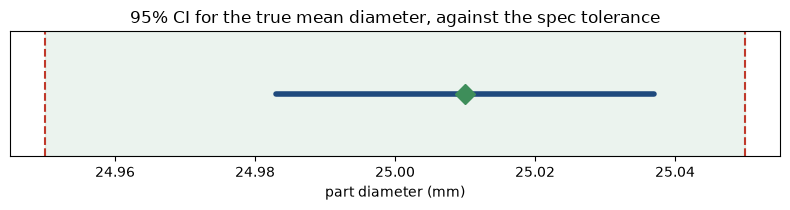

In [3]:
import matplotlib.pyplot as plt

part_target, part_tol = 25.00, 0.05
part_mean, part_sd, part_n = 25.01, 0.08, 36

part_se = part_sd / np.sqrt(part_n)
part_tstar = stats.t.ppf(0.975, df=part_n - 1)
part_margin = part_tstar * part_se
part_lo, part_hi = part_mean - part_margin, part_mean + part_margin
spec_lo, spec_hi = part_target - part_tol, part_target + part_tol

print(f'standard error  SE = {part_se:.4f}')
print(f'95% confidence interval: {part_lo:.3f} to {part_hi:.3f} mm')
print(f'spec tolerance:          {spec_lo:.2f} to {spec_hi:.2f} mm')

inside_spec = spec_lo <= part_lo and part_hi <= spec_hi
print('the whole interval sits inside spec: process is on target' if inside_spec
      else 'part of the interval falls outside spec: the process may need adjustment')

plt.figure(figsize=(8, 2.2))
plt.axvspan(spec_lo, spec_hi, color='#3E8E5A', alpha=0.1)
plt.axvline(spec_lo, color='#C0392B', ls='--')
plt.axvline(spec_hi, color='#C0392B', ls='--')
plt.plot([part_lo, part_hi], [0, 0], color='#1F497D', lw=4, solid_capstyle='round')
plt.plot(part_mean, 0, 'D', color='#3E8E5A', ms=10)
plt.yticks([]); plt.xlabel('part diameter (mm)')
plt.title('95% CI for the true mean diameter, against the spec tolerance')
plt.tight_layout(); plt.show()

## Step 4, what makes an interval wide or narrow

Three levers: the spread of the data, the sample size (through `sqrt(n)`), and the confidence level you demand. More confidence means a wider net; four times the data halves the margin.

Same sample, three confidence levels:
  90%: 1,377.43 to 1,514.41  (+/- 68.5)
  95%: 1,363.82 to 1,528.02  (+/- 82.1)
  99%: 1,336.43 to 1,555.41  (+/- 109.5)


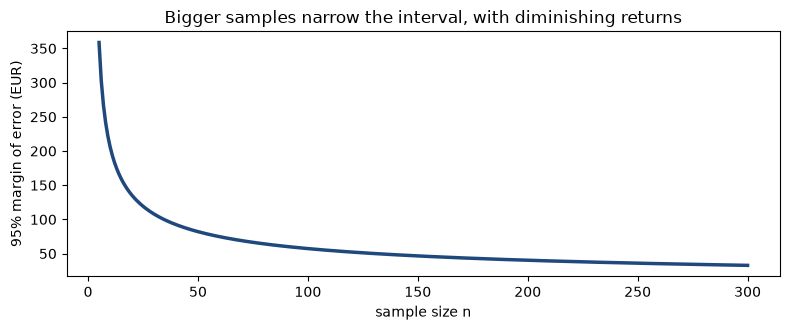

In [4]:
import matplotlib.pyplot as plt

print('Same sample, three confidence levels:')
for cl in (0.90, 0.95, 0.99):
    tc = stats.t.ppf(1 - (1 - cl) / 2, df=n - 1)
    m = tc * se
    print(f'  {cl:.0%}: {mean - m:,.2f} to {mean + m:,.2f}  (+/- {m:.1f})')

ns = np.arange(5, 301)
plt.figure(figsize=(8, 3.4))
plt.plot(ns, stats.t.ppf(0.975, ns - 1) * sd / np.sqrt(ns), color='#1F497D', lw=2.5)
plt.xlabel('sample size n'); plt.ylabel('95% margin of error (EUR)')
plt.title('Bigger samples narrow the interval, with diminishing returns')
plt.tight_layout(); plt.show()

## Step 5, what the 95% actually means

The interval is random; the true mean is fixed. The 95% is a property of the procedure: across many samples, about 95% of the intervals built this way catch the true mean. It is not a 95% probability for any one interval.

We can see it. Treat 1,445.92 as the true population mean, draw 100 fresh samples of 50, build an interval from each, and count how many capture the truth.

92 of 100 intervals caught the true mean (92%)


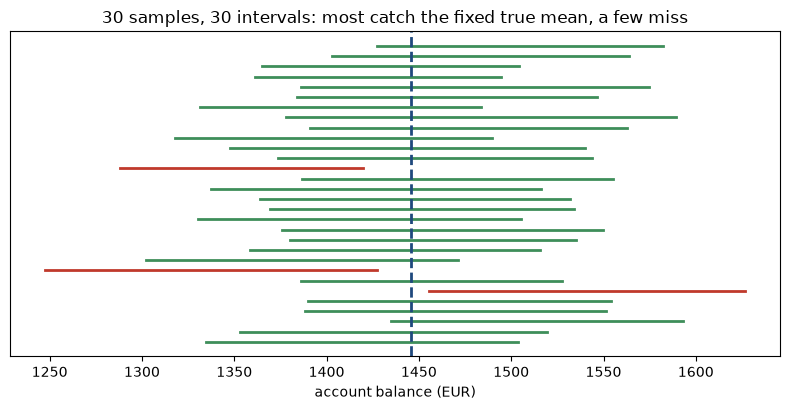

In [5]:
rng = np.random.default_rng(4)
true_mean = mean
n_sims = 100
caught = 0
intervals = []
for _ in range(n_sims):
    samp = rng.normal(true_mean, sd, n)
    m = samp.mean(); s = samp.std(ddof=1) / np.sqrt(n)
    clo, chi = m - tstar * s, m + tstar * s
    intervals.append((clo, chi, clo <= true_mean <= chi))
    caught += clo <= true_mean <= chi

print(f'{caught} of {n_sims} intervals caught the true mean ({caught / n_sims:.0%})')

plt.figure(figsize=(8, 4.2))
for i, (clo, chi, hit) in enumerate(intervals[:30]):
    col = '#3E8E5A' if hit else '#C0392B'
    plt.plot([clo, chi], [i, i], color=col, lw=2)
plt.axvline(true_mean, color='#1F497D', ls='--', lw=2)
plt.title('30 samples, 30 intervals: most catch the fixed true mean, a few miss')
plt.xlabel('account balance (EUR)'); plt.yticks([])
plt.tight_layout(); plt.show()

## Your call

Jot down, and push Claude on:
1. A colleague says "there is a 95% chance the true mean is between 1,363.82 and 1,528.02." In one sentence, why is that not quite right, and what is the correct reading?
2. The partner wants the interval half as wide. Roughly how much bigger must the sample be, and why is that expensive?
3. The recorded figure was 1,450 and we did not flag it. Does that prove the books are correct? What would a Type II error look like here?
4. The manufacturing interval sat entirely inside the spec tolerance. If it had straddled the lower spec limit instead, what would you recommend to the line supervisor, and is that a Type I or Type II concern?
5. Where does this exact move show up in the Deloitte audit-analytics capstone?